<a href="https://colab.research.google.com/github/IgooAlberto/melyani.github.io/blob/main/INDOBERT_SKRIPSI.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Analisis Sentimen Mahasiswa terhadap AI dalam Penyusunan Skripsi (IndoBERT)
Notebook revisi: bagian A (preprocessing + split + ROS) dipertahankan dari notebook asli dengan urutan preprocessing: cleaning → case folding → tokenizing → normalisasi → rejoin; bagian B menggantikan sel pelatihan/evaluasi lama.

**Perbaikan utama:** (1) model Non-ROS dan ROS disimpan di folder terpisah (sebelumnya saling menimpa), (2) satu fungsi eksperimen yang sama untuk kedua skenario, (3) pencarian kombinasi *learning rate* dan *max sequence length* sesuai proposal, dipilih dengan *macro F1* data validasi, (4) evaluasi data uji untuk KEDUA skenario + tabel perbandingan, (5) `ast.literal_eval` menggantikan `eval`.

**Gunakan GPU:** Runtime > Change runtime type > T4 GPU.

## A. Preprocessing, pembagian data, dan ROS
Urutan preprocessing: **Cleaning → Case Folding → Tokenizing → Normalisasi → Rejoin**.

In [8]:
import re
import string
import pandas as pd
from IPython.display import display

df = pd.read_csv(
    "/content/hasil_pelabelan_awal_2611.csv",
    encoding="latin1"
)

# Tampilkan kolom yang tersedia untuk memastikan kolom teks yang benar
print("Available columns in the DataFrame:")
print(df.columns)

# pastikan kolom teks
text_col = 'text_rejoin'

if 'id' not in df.columns:
    df['id'] = df.index

# hapus NaN & kosong
df = df.dropna(subset=[text_col])
df = df[df[text_col].astype(str).str.strip() != '']

# hapus duplikat (kunci pembanding dibuat huruf kecil agar duplikat yang
# hanya berbeda kapitalisasi tetap terdeteksi, teks aslinya tidak diubah)
kunci_duplikat = df[text_col].astype(str).str.lower().str.strip()
df = df[~kunci_duplikat.duplicated(keep="first")].copy()
jumlah_sebelum_cleaning = len(df)

def cleaning_text_safe(text):

    if pd.isna(text) or not str(text).strip():
        return ""
    text = str(text)

    # Ganti mention dengan 'user' & hapus tanda # (kata hashtag tetap disimpan)
    text = re.sub(r'@\w+', 'user', text)
    text = re.sub(r'#', '', text)

    # Ganti URL
    text = re.sub(r"(https?\S+|www\S+)", 'url', text, flags=re.IGNORECASE)

    # Tangani tanda hubung terlebih dahulu
    text = re.sub(r'(?<=\d)- (?=\d)', ' - ', text)
    text = re.sub(r'-(?!\d)', ' ', text)

    # Hapus tanda baca umum, tapi biarkan ! - . , (tanda tanya dihapus)
    tanda_penting = "!-. ,"
    tanda_baca = ''.join(ch for ch in string.punctuation if ch not in tanda_penting)
    for symbol in ['/', '&', '_', '|']:
        text = text.replace(symbol, ' ')

    text = text.translate(str.maketrans("", "", tanda_baca))

    # Hapus karakter aneh
    text = re.sub(r"[^\w\s,\.\-!…]", " ", text)

    # Hapus emoji
    emoji_pattern = re.compile(
        r"["
        u"\U0001F600-\U0001F64F"
        u"\U0001F300-\U0001F5FF"
        u"\U0001F680-\U0001F6FF"
        u"\U0001F1E0-\U0001F1FF"
        u"\U00002500-\U00002BEF"
        u"\U00002702-\U000027B0"
        u"\U0001F900-\U0001F9FF"
        u"\U0001FA70-\U0001FAFF"
        u"\U00002600-\U000026FF"
        u"\U00002700-\U000027BF"
        "]+", flags=re.UNICODE
    )
    text = emoji_pattern.sub("", text)

    # Rapikan spasi
    text = re.sub(r'\s+', ' ', text).strip()

    return text

df['clean_text'] = df[text_col].apply(cleaning_text_safe)

df = df.dropna(subset=['clean_text'])
df = df[df['clean_text'].str.strip() != '']

# Tabel Perbandingan
tabel_cleaning = df[['id', text_col, 'clean_text']].head(10)
display(
    tabel_cleaning.style.hide(axis="index")
)

# Simpan Hasil Cleaning
df[['id', text_col, 'clean_text']].to_csv("hasil_cleaning.csv", index=False)

print("Jumlah data sebelum cleaning (setelah hapus baris nan dan duplikat):", jumlah_sebelum_cleaning)
print("Jumlah data sesudah cleaning:", len(df))
print("\nTahap 1 selesai — File 'hasil_cleaning.csv' berhasil disimpan!")

Available columns in the DataFrame:
Index(['id', 'tokens_normalized', 'text_rejoin', 'label_manual_awal'], dtype='object')


id,text_rejoin,clean_text
1,lalu wakilkan saya di sempro,lalu wakilkan saya di sempro
2,"karya ilmiahku dibantu oleh chat gpt dan perplexity ,","karya ilmiahku dibantu oleh chat gpt dan perplexity ,"
3,saya ngerjain tugas akhir pakai chtgpt parafrase 5persen doang . omong saya lulus tahun ini dan udan wisuda berkat chtgpt,saya ngerjain tugas akhir pakai chtgpt parafrase 5persen doang . omong saya lulus tahun ini dan udan wisuda berkat chtgpt
4,serta referensi baju kebaya untuk wisuda,serta referensi baju kebaya untuk wisuda
5,yang skripsi angkatan jadul jauh sebelum covid tercengang melihat ini . ngerjain skripsi dengan membawa buku banyak dari berbagai sumber di perpus kampus .,yang skripsi angkatan jadul jauh sebelum covid tercengang melihat ini . ngerjain skripsi dengan membawa buku banyak dari berbagai sumber di perpus kampus .
6,"nanti kalau skripsi sudah jadi , nama mu akan abadi di skripsi ku","nanti kalau skripsi sudah jadi , nama mu akan abadi di skripsi ku"
7,pakai chat gpt turnitin hanya kena 6 anjirr mana pas sidang di terima dosen lagi haha,pakai chat gpt turnitin hanya kena 6 anjirr mana pas sidang di terima dosen lagi haha
8,grup yang sama sekali tidak pakai chat gpt ai buat skripsian,grup yang sama sekali tidak pakai chat gpt ai buat skripsian
9,prompt parafrase kakak,prompt parafrase kakak
10,saya langganan setahun pakai sciet ai haha puas sekali ngerjain tesis,saya langganan setahun pakai sciet ai haha puas sekali ngerjain tesis


Jumlah data sebelum cleaning (setelah hapus baris nan dan duplikat): 2611
Jumlah data sesudah cleaning: 2611

Tahap 1 selesai — File 'hasil_cleaning.csv' berhasil disimpan!


In [9]:
import pandas as pd
from IPython.display import display

df = pd.read_csv("hasil_cleaning.csv")

# case folding (dilakukan setelah cleaning)
df['case_folding_text'] = df['clean_text'].astype(str).str.lower().str.strip()

# Buang baris yang kosong setelah case folding
df = df[df['case_folding_text'] != '']

# Tabel Perbandingan
tabel_case_folding = df[['id', 'clean_text', 'case_folding_text']].head(10)
display(
    tabel_case_folding.style.hide(axis="index")
)

# Simpan Hasil Case Folding
df[['id', 'clean_text', 'case_folding_text']].to_csv("hasil_casefolding.csv", index=False)

print("Jumlah data setelah case folding:", len(df))
print("""
Tahap 2 selesai — File 'hasil_casefolding.csv' berhasil
disimpan!""")

id,clean_text,case_folding_text
1,lalu wakilkan saya di sempro,lalu wakilkan saya di sempro
2,"karya ilmiahku dibantu oleh chat gpt dan perplexity ,","karya ilmiahku dibantu oleh chat gpt dan perplexity ,"
3,saya ngerjain tugas akhir pakai chtgpt parafrase 5persen doang . omong saya lulus tahun ini dan udan wisuda berkat chtgpt,saya ngerjain tugas akhir pakai chtgpt parafrase 5persen doang . omong saya lulus tahun ini dan udan wisuda berkat chtgpt
4,serta referensi baju kebaya untuk wisuda,serta referensi baju kebaya untuk wisuda
5,yang skripsi angkatan jadul jauh sebelum covid tercengang melihat ini . ngerjain skripsi dengan membawa buku banyak dari berbagai sumber di perpus kampus .,yang skripsi angkatan jadul jauh sebelum covid tercengang melihat ini . ngerjain skripsi dengan membawa buku banyak dari berbagai sumber di perpus kampus .
6,"nanti kalau skripsi sudah jadi , nama mu akan abadi di skripsi ku","nanti kalau skripsi sudah jadi , nama mu akan abadi di skripsi ku"
7,pakai chat gpt turnitin hanya kena 6 anjirr mana pas sidang di terima dosen lagi haha,pakai chat gpt turnitin hanya kena 6 anjirr mana pas sidang di terima dosen lagi haha
8,grup yang sama sekali tidak pakai chat gpt ai buat skripsian,grup yang sama sekali tidak pakai chat gpt ai buat skripsian
9,prompt parafrase kakak,prompt parafrase kakak
10,saya langganan setahun pakai sciet ai haha puas sekali ngerjain tesis,saya langganan setahun pakai sciet ai haha puas sekali ngerjain tesis


Jumlah data setelah case folding: 2611

Tahap 2 selesai — File 'hasil_casefolding.csv' berhasil
disimpan!


In [10]:
# TOKENIZING

import pandas as pd
import nltk
from nltk.tokenize import word_tokenize
nltk.download('punkt')
nltk.download('punkt_tab') # Add this line to download the missing resource

df = pd.read_csv("hasil_casefolding.csv")

# FUNGSI TOKENIZING
def tokenize_text(teks):
    if not isinstance(teks, str) or teks.strip() == "":
        return []

    # Gunakan NLTK word_tokenize
    tokens = word_tokenize(teks)

    # Bersihkan token kosong atau spasi
    tokens = [t for t in tokens if t.strip() != ""]
    return tokens

df['tokens_nlp'] = df['case_folding_text'].apply(tokenize_text)
# Tabel Perbandingan
tabel_case_folding = df[['id','case_folding_text','tokens_nlp']].head(10)
display(
tabel_case_folding.style.hide(axis="index")
)

# Simpan Hasil Tokenizing
df[['id', 'case_folding_text',
'tokens_nlp']].to_csv("hasil_tokenizing.csv", index=False)
print("""
Tahap 3 selesai — File 'hasil_tokenizing.csv' berhasil
disimpan!""")

[nltk_data] Downloading package punkt to /root/nltk_data...
[nltk_data]   Package punkt is already up-to-date!
[nltk_data] Downloading package punkt_tab to /root/nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!


id,case_folding_text,tokens_nlp
1,lalu wakilkan saya di sempro,"['lalu', 'wakilkan', 'saya', 'di', 'sempro']"
2,"karya ilmiahku dibantu oleh chat gpt dan perplexity ,","['karya', 'ilmiahku', 'dibantu', 'oleh', 'chat', 'gpt', 'dan', 'perplexity', ',']"
3,saya ngerjain tugas akhir pakai chtgpt parafrase 5persen doang . omong saya lulus tahun ini dan udan wisuda berkat chtgpt,"['saya', 'ngerjain', 'tugas', 'akhir', 'pakai', 'chtgpt', 'parafrase', '5persen', 'doang', '.', 'omong', 'saya', 'lulus', 'tahun', 'ini', 'dan', 'udan', 'wisuda', 'berkat', 'chtgpt']"
4,serta referensi baju kebaya untuk wisuda,"['serta', 'referensi', 'baju', 'kebaya', 'untuk', 'wisuda']"
5,yang skripsi angkatan jadul jauh sebelum covid tercengang melihat ini . ngerjain skripsi dengan membawa buku banyak dari berbagai sumber di perpus kampus .,"['yang', 'skripsi', 'angkatan', 'jadul', 'jauh', 'sebelum', 'covid', 'tercengang', 'melihat', 'ini', '.', 'ngerjain', 'skripsi', 'dengan', 'membawa', 'buku', 'banyak', 'dari', 'berbagai', 'sumber', 'di', 'perpus', 'kampus', '.']"
6,"nanti kalau skripsi sudah jadi , nama mu akan abadi di skripsi ku","['nanti', 'kalau', 'skripsi', 'sudah', 'jadi', ',', 'nama', 'mu', 'akan', 'abadi', 'di', 'skripsi', 'ku']"
7,pakai chat gpt turnitin hanya kena 6 anjirr mana pas sidang di terima dosen lagi haha,"['pakai', 'chat', 'gpt', 'turnitin', 'hanya', 'kena', '6', 'anjirr', 'mana', 'pas', 'sidang', 'di', 'terima', 'dosen', 'lagi', 'haha']"
8,grup yang sama sekali tidak pakai chat gpt ai buat skripsian,"['grup', 'yang', 'sama', 'sekali', 'tidak', 'pakai', 'chat', 'gpt', 'ai', 'buat', 'skripsian']"
9,prompt parafrase kakak,"['prompt', 'parafrase', 'kakak']"
10,saya langganan setahun pakai sciet ai haha puas sekali ngerjain tesis,"['saya', 'langganan', 'setahun', 'pakai', 'sciet', 'ai', 'haha', 'puas', 'sekali', 'ngerjain', 'tesis']"



Tahap 3 selesai — File 'hasil_tokenizing.csv' berhasil
disimpan!


In [11]:
import ast
import pandas as pd
import re

df = pd.read_csv("hasil_tokenizing.csv")
# Jika kolom tokens_nlp berbentuk string, ubah jadi list
df['tokens_nlp'] = df['tokens_nlp'].apply(lambda x: ast.literal_eval(x) if isinstance(x, str) else x)

# Kamus Slang
df_slang = pd.read_csv("/content/Kamus_Slang_updated.csv")
slang_dict = dict(zip(df_slang['Slang'], df_slang['Formal']))

# Kamus Tambahan
kamus_jawa = {
    "ra": "tidak",
    "ora": "tidak",
    "gak": "tidak",
    "nggak": "tidak",
    "ngerti": "paham",
    "mudeng": "paham",
    "ngeh": "paham",
    "mumet": "bingung",
    "puyeng": "pusing"
}
kamus_tambahan = {
    "krg": "kurang",
    "blm": "belum",
    "lu": "kamu",
    "bg": "bang",
    "sy": "saya",
    "gk": "tidak",
    "ga": "tidak",
    "gaa": "tidak",
    "gabisa": "tidak bisa",
    "gabisah": "tidak bisa",
    "gabisaa": "tidak bisa"
}

# Gabung semua kamus
combined_dict = {**slang_dict, **kamus_jawa, **kamus_tambahan}

# Normalisasi Tawa (wkwk → haha)
def normalisasi_tawa(kata):
    return re.sub(
        r'(?i)((ha){2,}|(he){2,}|(hi){2,}|(wk){2,}|(kw){2,}|lol+|lmao+)',
        'haha',
        kata,
        flags=re.IGNORECASE
    )

# Normalisasi Berantai
def normalisasi_berantai(kata, kamus):
    kata = kata.lower().strip()	# penting tetap ada, untuk matching di kamus
    visited = set()

    while kata in kamus and kata not in visited:
        visited.add(kata)
        kata = kamus[kata]

    return kata

# Normalisasi Token
def normalize_tokens(tokens):
    hasil = []
    if not isinstance(tokens, (list, tuple)):
        return hasil

    for t in tokens:
        if not isinstance(t, str):
            continue
        kata = t # pakai token asli

        if not kata:
            continue
        # Normalisasi berantai (slang → formal)
        kata_norm = normalisasi_berantai(kata, combined_dict)

        # Normalisasi tawa
        kata_norm = normalisasi_tawa(kata_norm)

        if kata_norm:
            hasil.append(kata_norm)

    return hasil

df['tokens_normalized'] = df['tokens_nlp'].apply(normalize_tokens)

# Penyesuaian gaya bahasa
df['tokens_normalized'] = df['tokens_normalized'].apply(
    lambda toks: ["saya" if t == "aku" else t for t in toks]
)

# Tabel Perbandingan
tabel_case_folding = df[['id','tokens_nlp','tokens_normalized']].head(10)

display(
    tabel_case_folding.style.hide(axis="index")
)

# Simpan Hasil Normalisasi
df[['id', 'tokens_nlp', 'tokens_normalized']].to_csv(
    "hasil_normalisasi.csv", index=False
)

print("""
Tahap 4 selesai — File 'hasil_normalisasi.csv' berhasil
disimpan!""")

id,tokens_nlp,tokens_normalized
1,"['lalu', 'wakilkan', 'saya', 'di', 'sempro']","['lalu', 'wakilkan', 'saya', 'di', 'seminar proposal']"
2,"['karya', 'ilmiahku', 'dibantu', 'oleh', 'chat', 'gpt', 'dan', 'perplexity', ',']","['karya', 'ilmiahku', 'dibantu', 'oleh', 'chat', 'gpt', 'dan', 'perplexity', ',']"
3,"['saya', 'ngerjain', 'tugas', 'akhir', 'pakai', 'chtgpt', 'parafrase', '5persen', 'doang', '.', 'omong', 'saya', 'lulus', 'tahun', 'ini', 'dan', 'udan', 'wisuda', 'berkat', 'chtgpt']","['saya', 'mengerjakan', 'tugas', 'akhir', 'pakai', 'chatgpt', 'parafrase', '5persen', 'saja', '.', 'omong', 'saya', 'lulus', 'tahun', 'ini', 'dan', 'sudah', 'wisuda', 'berkat', 'chatgpt']"
4,"['serta', 'referensi', 'baju', 'kebaya', 'untuk', 'wisuda']","['serta', 'referensi', 'baju', 'kebaya', 'untuk', 'wisuda']"
5,"['yang', 'skripsi', 'angkatan', 'jadul', 'jauh', 'sebelum', 'covid', 'tercengang', 'melihat', 'ini', '.', 'ngerjain', 'skripsi', 'dengan', 'membawa', 'buku', 'banyak', 'dari', 'berbagai', 'sumber', 'di', 'perpus', 'kampus', '.']","['yang', 'skripsi', 'angkatan', 'zaman dulu', 'jauh', 'sebelum', 'covid', 'tercengang', 'melihat', 'ini', '.', 'mengerjakan', 'skripsi', 'dengan', 'membawa', 'buku', 'banyak', 'dari', 'berbagai', 'sumber', 'di', 'perpus', 'kampus', '.']"
6,"['nanti', 'kalau', 'skripsi', 'sudah', 'jadi', ',', 'nama', 'mu', 'akan', 'abadi', 'di', 'skripsi', 'ku']","['nanti', 'kalau', 'skripsi', 'sudah', 'jadi', ',', 'nama', 'mu', 'akan', 'abadi', 'di', 'skripsi', 'saya']"
7,"['pakai', 'chat', 'gpt', 'turnitin', 'hanya', 'kena', '6', 'anjirr', 'mana', 'pas', 'sidang', 'di', 'terima', 'dosen', 'lagi', 'haha']","['pakai', 'chat', 'gpt', 'turnitin', 'hanya', 'kena', '6', 'anjing', 'mana', 'pas', 'sidang', 'di', 'terima', 'dosen', 'lagi', 'tertawa']"
8,"['grup', 'yang', 'sama', 'sekali', 'tidak', 'pakai', 'chat', 'gpt', 'ai', 'buat', 'skripsian']","['grup', 'yang', 'sama', 'sekali', 'tidak', 'pakai', 'chat', 'gpt', 'ai', 'buat', 'skripsian']"
9,"['prompt', 'parafrase', 'kakak']","['prompt', 'parafrase', 'kakak']"
10,"['saya', 'langganan', 'setahun', 'pakai', 'sciet', 'ai', 'haha', 'puas', 'sekali', 'ngerjain', 'tesis']","['saya', 'langganan', 'setahun', 'pakai', 'sciet', 'ai', 'tertawa', 'puas', 'sekali', 'mengerjakan', 'tesis']"



Tahap 4 selesai — File 'hasil_normalisasi.csv' berhasil
disimpan!


In [12]:
import ast
# REJOIN TEKS

import pandas as pd
from tqdm import tqdm

print("Membaca file hasil token per kata...")
df = pd.read_csv("hasil_normalisasi.csv")

# Pastikan kolom tokens_normalized ada
if 'tokens_normalized' not in df.columns:
    raise ValueError("⚠ Kolom 'tokens_normalized' tidak ditemukan. Pastikan file hasil_normalisasi.csv benar.")

# Jika kolom token disimpan dalam format string list (mis. "['kata','kata']"), ubah jadi list Python
df['tokens_normalized'] = df['tokens_normalized'].apply(lambda x: ast.literal_eval(x) if isinstance(x, str) else x)

print(f"File berhasil dimuat! Total data: {len(df)} baris\n")
# Rejoin teks dari token list ke kalimat
tqdm.pandas()

def rejoin_tokens(tokens):
    if isinstance(tokens, list):
        return " ".join(tokens)
    return ""

print("Mengubah token menjadi teks utuh...")
df['text_rejoin'] = df['tokens_normalized'].progress_apply(rejoin_tokens)

# Tabel Perbandingan
tabel_case_folding = df[['id','tokens_normalized',
'text_rejoin']].head(10)

display(
tabel_case_folding.style.hide(axis="index")
)

# Simpan Hasil Rejoin
output_path = "hasil_rejoin.csv"
df[['id', 'tokens_normalized',
'text_rejoin']].to_csv(output_path, index=False)

print("""
Tahap 5 selesai — File 'hasil_rejoin.csv' berhasil disimpan!""")

Membaca file hasil token per kata...
File berhasil dimuat! Total data: 2611 baris

Mengubah token menjadi teks utuh...


100%|██████████| 2611/2611 [00:00<00:00, 384378.50it/s]


id,tokens_normalized,text_rejoin
1,"['lalu', 'wakilkan', 'saya', 'di', 'seminar proposal']",lalu wakilkan saya di seminar proposal
2,"['karya', 'ilmiahku', 'dibantu', 'oleh', 'chat', 'gpt', 'dan', 'perplexity', ',']","karya ilmiahku dibantu oleh chat gpt dan perplexity ,"
3,"['saya', 'mengerjakan', 'tugas', 'akhir', 'pakai', 'chatgpt', 'parafrase', '5persen', 'saja', '.', 'omong', 'saya', 'lulus', 'tahun', 'ini', 'dan', 'sudah', 'wisuda', 'berkat', 'chatgpt']",saya mengerjakan tugas akhir pakai chatgpt parafrase 5persen saja . omong saya lulus tahun ini dan sudah wisuda berkat chatgpt
4,"['serta', 'referensi', 'baju', 'kebaya', 'untuk', 'wisuda']",serta referensi baju kebaya untuk wisuda
5,"['yang', 'skripsi', 'angkatan', 'zaman dulu', 'jauh', 'sebelum', 'covid', 'tercengang', 'melihat', 'ini', '.', 'mengerjakan', 'skripsi', 'dengan', 'membawa', 'buku', 'banyak', 'dari', 'berbagai', 'sumber', 'di', 'perpus', 'kampus', '.']",yang skripsi angkatan zaman dulu jauh sebelum covid tercengang melihat ini . mengerjakan skripsi dengan membawa buku banyak dari berbagai sumber di perpus kampus .
6,"['nanti', 'kalau', 'skripsi', 'sudah', 'jadi', ',', 'nama', 'mu', 'akan', 'abadi', 'di', 'skripsi', 'saya']","nanti kalau skripsi sudah jadi , nama mu akan abadi di skripsi saya"
7,"['pakai', 'chat', 'gpt', 'turnitin', 'hanya', 'kena', '6', 'anjing', 'mana', 'pas', 'sidang', 'di', 'terima', 'dosen', 'lagi', 'tertawa']",pakai chat gpt turnitin hanya kena 6 anjing mana pas sidang di terima dosen lagi tertawa
8,"['grup', 'yang', 'sama', 'sekali', 'tidak', 'pakai', 'chat', 'gpt', 'ai', 'buat', 'skripsian']",grup yang sama sekali tidak pakai chat gpt ai buat skripsian
9,"['prompt', 'parafrase', 'kakak']",prompt parafrase kakak
10,"['saya', 'langganan', 'setahun', 'pakai', 'sciet', 'ai', 'tertawa', 'puas', 'sekali', 'mengerjakan', 'tesis']",saya langganan setahun pakai sciet ai tertawa puas sekali mengerjakan tesis



Tahap 5 selesai — File 'hasil_rejoin.csv' berhasil disimpan!


 Membaca file proses: hasil_rejoin.csv ...
 Membaca label dari file awal: /content/hasil_pelabelan_awal_2611.csv ...
 Dataset dimuat (2611 baris, 4 kolom)

Membersihkan kolom label dari spasi, NaN, dan karakter
tak terlihat...
Distribusi awal label (termasuk kemungkinan kosong):
label_manual_awal
Netral     1320
Positif    1056
Negatif     235
Name: count, dtype: int64 

✅ Data berlabel	: 2611 baris
⚠️ Data tanpa label: 0 baris (tidak diproses, disimpan terpisah)

Data tanpa label disimpan: data_unlabeled+val.csv

Distribusi label sebelum split:
label_manual_awal
Netral     1320
Positif    1056
Negatif     235
Name: count, dtype: int64 

Membagi data berlabel menjadi TRAIN (80%), VALIDATION
(10%), dan TEST (10%) ...
Distribusi TRAIN (80%): 2088 baris
label_manual_awal
Netral     1056
Positif     844
Negatif     188
Name: count, dtype: int64 

Distribusi VALIDATION (10%): 261 baris
label_manual_awal
Netral     132
Positif    106
Negatif     23
Name: count, dtype: int64 

Distribusi TEST

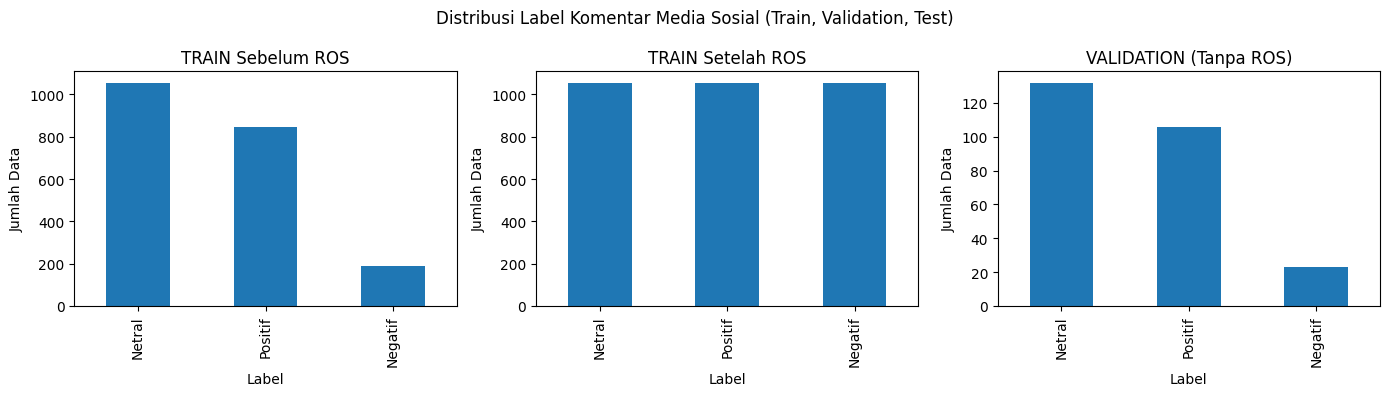


Split selesai — proporsi total:
 TRAIN (before ROS) : 2088 data
 TRAIN (after ROS) : 3168 data
 VALIDATION	: 261 data
 TEST	: 262 data

Siap digunakan untuk fine-tuning IndoBERT (train+val).


In [13]:
import pandas as pd
from sklearn.model_selection import train_test_split
from imblearn.over_sampling import RandomOverSampler
import matplotlib.pyplot as plt

# Load Data Preprocess
processed_data_file = "hasil_rejoin.csv"
# The original labels are in hasil_pelabelan_awal_2611.csv under the column 'label_manual_awal'
original_labeled_data_file = "/content/hasil_pelabelan_awal_2611.csv"
label_col = "label_manual_awal" # Correct label column name

print(f" Membaca file proses: {processed_data_file} ...")
df_processed = pd.read_csv(processed_data_file)

print(f" Membaca label dari file awal: {original_labeled_data_file} ...")
df_original_labels = pd.read_csv(original_labeled_data_file, encoding="latin1")

# Merge the labels from the original file into the processed dataframe
df = pd.merge(df_processed, df_original_labels[['id', label_col]], on='id', how='left')

print(
    f" Dataset dimuat ({len(df)} baris, {len(df.columns)}"
    " kolom)\n"
)

# Bersihkan Kolom Label
print("Membersihkan kolom label dari spasi, NaN, dan karakter\ntak terlihat...")

df[label_col] = df[label_col].astype(str).str.strip()
df = df.replace({label_col: {"nan": None, "": None, " ": None,
"None": None}})

print("Distribusi awal label (termasuk kemungkinan kosong):")
print(df[label_col].value_counts(dropna=False), "\n")

# Pisahkan Data Berlabel dan Tanpa Label
labeled_df = df.dropna(subset=[label_col])
unlabeled_df = df[df[label_col].isna()]

print(f"✅ Data berlabel\t: {len(labeled_df)} baris")
print(f"⚠️ Data tanpa label: {len(unlabeled_df)} baris (tidak diproses, disimpan terpisah)\n")

# Simpan Data Tanpa Label
unlabeled_file = "data_unlabeled+val.csv"
unlabeled_df.to_csv(unlabeled_file, index=False, encoding='utf-8-sig')
print(f"Data tanpa label disimpan: {unlabeled_file}\n")

# Distribusi Label Sebelum Split
print("Distribusi label sebelum split:")
print(labeled_df[label_col].value_counts(), "\n")

# SPLIT DATA BERLABEL → 80% TRAIN, 10% VAL, 10% TEST
print("Membagi data berlabel menjadi TRAIN (80%), VALIDATION\n(10%), dan TEST (10%) ...")
# Tahap 1: Pisahkan TEST (10%)
train_val_df, test_df = train_test_split(
labeled_df,
test_size=0.1,
random_state=42,
stratify=labeled_df[label_col]
)

# Tahap 2: Pisahkan TRAIN (80%) dan VAL (10%) dari sisanya
# (90%)
train_df, val_df = train_test_split(
train_val_df,
test_size=(0.1 / 0.9), # ≈ 10% total
random_state=42,
stratify=train_val_df[label_col]
)

print(f"Distribusi TRAIN (80%): {len(train_df)} baris")
print(train_df[label_col].value_counts(), "\n")

print(f"Distribusi VALIDATION (10%): {len(val_df)} baris")
print(val_df[label_col].value_counts(), "\n")

print(f"Distribusi TEST (10%): {len(test_df)} baris")
print(test_df[label_col].value_counts(), "\n")

#Simpan TRAIN Sebelum ROS
train_file_before_ros = "train_80%.csv"
train_df.to_csv(train_file_before_ros, index=False,
encoding='utf-8-sig')
print(f"Train sebelum ROS disimpan: {train_file_before_ros}\n({len(train_df)} baris)\n")

# Terapkan RANDOM OVER SAMPLER (HANYA TRAIN)
print("Menyeimbangkan data TRAIN menggunakan RandomOverSampler\n...")

X_train = train_df.drop(columns=[label_col])
y_train = train_df[label_col]

ros = RandomOverSampler(random_state=42)
X_train_res, y_train_res = ros.fit_resample(X_train, y_train)

train_df_ros = pd.DataFrame(X_train_res,
columns=X_train.columns)
train_df_ros[label_col] = y_train_res

print("Distribusi TRAIN setelah ROS:")
print(train_df_ros[label_col].value_counts(), "\n")
# Simpan Semua Hasil
train_ros_file = "train_ROS80%.csv"
val_file = "val_10%.csv"
test_file = "test_10%.csv"

train_df_ros.to_csv(train_ros_file, index=False, encoding='utf-8-sig')
val_df.to_csv(val_file, index=False, encoding='utf-8-sig')
test_df.to_csv(test_file, index=False, encoding='utf-8-sig')

print("✅ Semua hasil disimpan:")
print(f"\t• Train sebelum ROS : {train_file_before_ros}\n({len(train_df)} baris)")
print(f"\t• Train setelah ROS : {train_ros_file}\n({len(train_df_ros)} baris)")
print(
    f"\t• Validation\t: {val_file} ({len(val_df)}\n"
    "baris)"
)
print(
    f"\t• Test\t: {test_file} ({len(test_df)}\n"
    "baris)"
)
print(f"\t• Unlabeled\t: {unlabeled_file}\n")

# Visualisasi Distribusi Label
fig, axes = plt.subplots(1, 3, figsize=(14, 4))

train_df[label_col].value_counts().plot(kind='bar', ax=axes[0],
title='TRAIN Sebelum ROS')
train_df_ros[label_col].value_counts().plot(kind='bar',
ax=axes[1], title='TRAIN Setelah ROS')
val_df[label_col].value_counts().plot(kind='bar', ax=axes[2],
title='VALIDATION (Tanpa ROS)')

for ax in axes:
    ax.set_xlabel("Label")
    ax.set_ylabel("Jumlah Data")
plt.suptitle("Distribusi Label Komentar Media Sosial (Train, Validation, Test)")
plt.tight_layout()
plt.show()

# Ringkasan Akhir
print("\nSplit selesai — proporsi total:")
print(f" TRAIN (before ROS) : {len(train_df)} data")
print(f" TRAIN (after ROS) : {len(train_df_ros)} data")
print(f" VALIDATION\t: {len(val_df)} data")
print(f" TEST\t: {len(test_df)} data")
print("\nSiap digunakan untuk fine-tuning IndoBERT (train+val).")

## B. Fine-tuning IndoBERT: Non-ROS vs ROS

In [14]:
# ===================== SETUP & KONFIGURASI =====================
import os, random, copy, json
import numpy as np
import pandas as pd
import torch
from torch.utils.data import Dataset, DataLoader
from transformers import AutoTokenizer, BertForSequenceClassification, DataCollatorWithPadding
from sklearn.metrics import (classification_report, confusion_matrix,
                             accuracy_score, precision_recall_fscore_support, f1_score)
import seaborn as sns
import matplotlib.pyplot as plt
from tqdm.auto import tqdm

SEED = 42
def set_seed(seed=SEED):
    random.seed(seed); np.random.seed(seed)
    torch.manual_seed(seed); torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)
if device.type == "cpu":
    print("PERINGATAN: berjalan di CPU (sangat lambat, ~1 jam/epoch). Aktifkan GPU T4 di Colab.")

MODEL_NAME = "indobenchmark/indobert-base-p1"
TEXT_COL, LABEL_COL = "text_rejoin", "label_manual_awal"
label_map = {"Netral": 0, "Positif": 1, "Negatif": 2}
id2label  = {v: k for k, v in label_map.items()}
CLASS_NAMES = [id2label[i] for i in range(3)]

# Hyperparameter tetap (sama untuk kedua skenario agar perbandingan adil)
BATCH_TRAIN, BATCH_EVAL, NUM_EPOCHS = 16, 32, 3

# Ruang pencarian sesuai proposal: learning rate & maximum sequence length
GRID_LR      = [5e-6, 2e-5, 5e-5]
GRID_MAX_LEN = [64, 128]

SCENARIOS = {
    "NonROS": "train_80%.csv",     # data latih asli (tidak seimbang)
    "ROS":    "train_ROS80%.csv",  # data latih setelah Random Over Sampling
}
VAL_FILE, TEST_FILE = "val_10%.csv", "test_10%.csv"

tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)

def load_split(path):
    df = pd.read_csv(path, encoding="utf-8-sig")
    df[TEXT_COL]  = df[TEXT_COL].astype(str).str.strip()
    df[LABEL_COL] = df[LABEL_COL].astype(str).str.strip()
    df = df[df[LABEL_COL].isin(label_map)].copy()
    df["y"] = df[LABEL_COL].map(label_map)
    return df.reset_index(drop=True)

df_val, df_test = load_split(VAL_FILE), load_split(TEST_FILE)
train_dfs = {k: load_split(v) for k, v in SCENARIOS.items()}
for k, d in train_dfs.items():
    print(k, "train:", len(d), d[LABEL_COL].value_counts().to_dict())
print("val:", len(df_val), "| test:", len(df_test))

Device: cuda


config.json:   0%|          | 0.00/1.53k [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/2.00 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/229k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]

NonROS train: 2088 {'Netral': 1056, 'Positif': 844, 'Negatif': 188}
ROS train: 3168 {'Netral': 1056, 'Positif': 1056, 'Negatif': 1056}
val: 261 | test: 262


In [15]:
# ===================== DATASET & FUNGSI EVALUASI =====================
class TextDataset(Dataset):
    """Tokenisasi sekali di awal, padding dinamis per batch lewat DataCollatorWithPadding."""
    def __init__(self, df, max_len):
        enc = tokenizer(df[TEXT_COL].tolist(), truncation=True, max_length=max_len)
        self.enc, self.y = enc, df["y"].tolist()
    def __len__(self): return len(self.y)
    def __getitem__(self, i):
        item = {k: v[i] for k, v in self.enc.items()}
        item["labels"] = self.y[i]
        return item

collator = DataCollatorWithPadding(tokenizer)

def make_loader(df, max_len, batch, shuffle=False, seed=SEED):
    g = torch.Generator(); g.manual_seed(seed)
    return DataLoader(TextDataset(df, max_len), batch_size=batch, shuffle=shuffle,
                      collate_fn=collator, generator=g if shuffle else None)

@torch.no_grad()
def predict(model, loader):
    model.eval()
    ys, ps, probs = [], [], []
    for batch in loader:
        batch = {k: v.to(device) for k, v in batch.items()}
        logits = model(**{k: v for k, v in batch.items() if k != "labels"}).logits
        p = torch.softmax(logits, dim=1)
        ys += batch["labels"].cpu().tolist()
        ps += p.argmax(1).cpu().tolist()
        probs += p.cpu().tolist()
    return np.array(ys), np.array(ps), np.array(probs)

def metrics(y, p):
    pr, rc, f1, _ = precision_recall_fscore_support(y, p, average="macro", zero_division=0)
    return {"accuracy": accuracy_score(y, p), "precision_macro": pr,
            "recall_macro": rc, "f1_macro": f1}


In [16]:
# ===================== FUNGSI EKSPERIMEN (dipakai untuk KEDUA skenario) =====================
def run_experiment(scenario, lr, max_len):
    set_seed(SEED)                     # seed identik di setiap percobaan
    df_train = train_dfs[scenario]
    train_loader = make_loader(df_train, max_len, BATCH_TRAIN, shuffle=True)
    val_loader   = make_loader(df_val,   max_len, BATCH_EVAL)

    model = BertForSequenceClassification.from_pretrained(
        MODEL_NAME, num_labels=3, id2label=id2label, label2id=label_map,
        ignore_mismatched_sizes=True).to(device)
    optimizer = torch.optim.AdamW(model.parameters(), lr=lr)

    best = {"f1_macro": -1}; best_state = None; history = []
    for epoch in range(1, NUM_EPOCHS + 1):
        model.train(); total, tr_y, tr_p = 0.0, [], []
        for batch in tqdm(train_loader, desc=f"{scenario} lr={lr} len={max_len} ep{epoch}", leave=False):
            batch = {k: v.to(device) for k, v in batch.items()}
            out = model(**batch)
            out.loss.backward(); optimizer.step(); optimizer.zero_grad()
            total += out.loss.item()
            tr_y += batch["labels"].cpu().tolist(); tr_p += out.logits.argmax(1).cpu().tolist()
        yv, pv, _ = predict(model, val_loader)
        m = metrics(yv, pv)
        history.append({"epoch": epoch, "train_loss": total/len(train_loader),
                        "train_acc": accuracy_score(tr_y, tr_p),
                        "val_acc": m["accuracy"], "val_f1_macro": m["f1_macro"]})
        print(f"[{scenario}] lr={lr} len={max_len} ep{epoch}: "
              f"loss={history[-1]['train_loss']:.4f} train_acc={history[-1]['train_acc']:.4f} "
              f"val_acc={m['accuracy']:.4f} val_macroF1={m['f1_macro']:.4f}")
        # pilih epoch terbaik berdasarkan MACRO F1 (bukan akurasi) karena kelas tidak seimbang
        if m["f1_macro"] > best["f1_macro"]:
            best = {**m, "epoch": epoch}
            best_state = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}

    model.load_state_dict(best_state)
    return model, best, pd.DataFrame(history)

# ===================== PENCARIAN HYPERPARAMETER PER SKENARIO =====================
os.makedirs("models", exist_ok=True)
results, best_per_scenario = [], {}

for scenario in SCENARIOS:
    for lr in GRID_LR:
        for max_len in GRID_MAX_LEN:
            model, best, hist = run_experiment(scenario, lr, max_len)
            results.append({"scenario": scenario, "lr": lr, "max_len": max_len, **best})
            cur = best_per_scenario.get(scenario)
            if cur is None or best["f1_macro"] > cur["f1_macro"]:
                best_per_scenario[scenario] = {"lr": lr, "max_len": max_len, "history": hist, **best}
                save_dir = f"models/{scenario}_best"          # folder TERPISAH per skenario
                model.save_pretrained(save_dir); tokenizer.save_pretrained(save_dir)
                json.dump({"lr": lr, "max_len": max_len, "epoch": best["epoch"]},
                          open(f"{save_dir}/config_eksperimen.json", "w"))
            del model; torch.cuda.empty_cache()

df_grid = pd.DataFrame(results).sort_values(["scenario", "f1_macro"], ascending=[True, False])
df_grid.to_csv("hasil_hyperparameter_validasi.csv", index=False)
display(df_grid.round(4))


[transformers] You passed `num_labels=3` which is incompatible to the `id2label` map of length `5`.


pytorch_model.bin: reconstructing file:   0%|          |  0.00B /  498MB            

pytorch_model.bin: downloading bytes:           |  0.00B            

model.safetensors: reconstructing file:   0%|          |  0.00B /  498MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

... (109 outputs left out)

[ROS] lr=5e-05 len=128 ep2: loss=0.2397 train_acc=0.9129 val_acc=0.8391 val_macroF1=0.8408


ROS lr=5e-05 len=128 ep3:   0%|          | 0/198 [00:00<?, ?it/s]

[ROS] lr=5e-05 len=128 ep3: loss=0.1432 train_acc=0.9441 val_acc=0.8276 val_macroF1=0.8400


,scenario,lr,max_len,accuracy,precision_macro,recall_macro,f1_macro,epoch
4,NonROS,0.0,64,0.8467,0.8751,0.8732,0.8645,3
5,NonROS,0.0,128,0.8429,0.8404,0.8424,0.8382,2
2,NonROS,0.0,64,0.8467,0.8436,0.8361,0.8341,2
3,NonROS,0.0,128,0.8161,0.8104,0.8474,0.8223,3
1,NonROS,0.0,128,0.8046,0.7732,0.7837,0.7715,3
0,NonROS,0.0,64,0.8046,0.7491,0.7831,0.7585,3
8,ROS,0.0,64,0.8582,0.8722,0.8645,0.8663,2
9,ROS,0.0,128,0.8391,0.8462,0.8657,0.8486,1
6,ROS,0.0,64,0.8467,0.8453,0.8575,0.8478,3
11,ROS,0.0,128,0.8391,0.8370,0.8450,0.8408,2


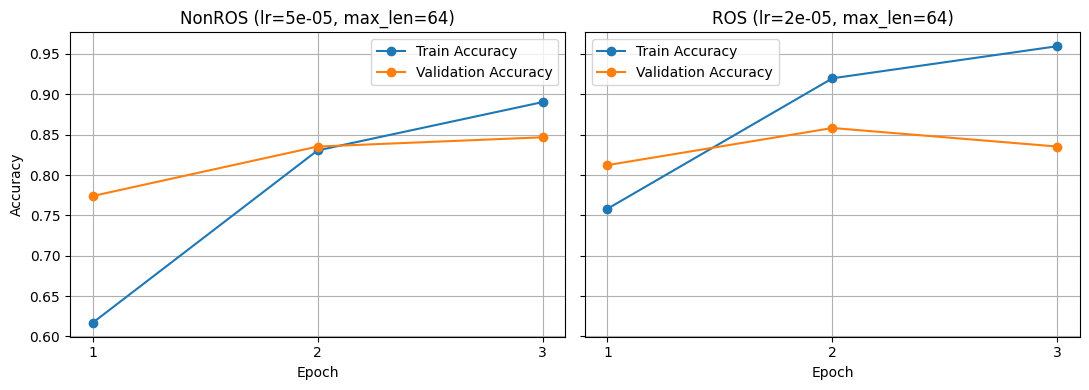

In [17]:
# ===================== LEARNING CURVE (konfigurasi terbaik tiap skenario) =====================
fig, axes = plt.subplots(1, 2, figsize=(11, 4), sharey=True)
for ax, (sc, b) in zip(axes, best_per_scenario.items()):
    h = b["history"]
    ax.plot(h["epoch"], h["train_acc"], marker="o", label="Train Accuracy")
    ax.plot(h["epoch"], h["val_acc"],   marker="o", label="Validation Accuracy")
    ax.set_title(f"{sc} (lr={b['lr']}, max_len={b['max_len']})")
    ax.set_xlabel("Epoch"); ax.set_xticks(h["epoch"]); ax.grid(True); ax.legend()
axes[0].set_ylabel("Accuracy"); plt.tight_layout(); plt.show()


Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]


===== NonROS  (lr=5e-05, max_len=64) =====
              precision    recall  f1-score   support

      Netral     0.9346    0.7576    0.8368       132
     Positif     0.7634    0.9434    0.8439       106
     Negatif     0.9167    0.9167    0.9167        24

    accuracy                         0.8473       262
   macro avg     0.8715    0.8725    0.8658       262
weighted avg     0.8637    0.8473    0.8470       262



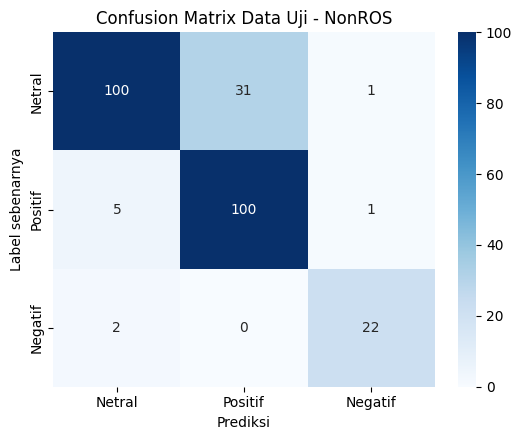

Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]


===== ROS  (lr=2e-05, max_len=64) =====
              precision    recall  f1-score   support

      Netral     0.8968    0.8561    0.8760       132
     Positif     0.8261    0.8962    0.8597       106
     Negatif     0.9524    0.8333    0.8889        24

    accuracy                         0.8702       262
   macro avg     0.8918    0.8619    0.8749       262
weighted avg     0.8733    0.8702    0.8706       262



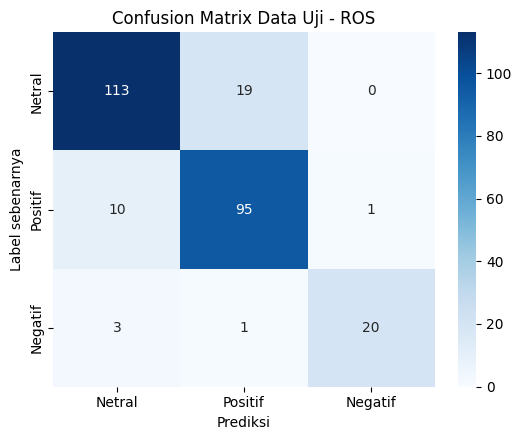


=== PERBANDINGAN DATA UJI (jawaban Rumusan Masalah) ===


,Skenario,lr,max_len,accuracy,precision_macro,recall_macro,f1_macro,F1_Netral,F1_Positif,F1_Negatif
0,NonROS,0.0,64,0.8473,0.8715,0.8725,0.8658,0.8368,0.8439,0.9167
1,ROS,0.0,64,0.8702,0.8918,0.8619,0.8749,0.8760,0.8597,0.8889


In [18]:
# ===================== EVALUASI DATA UJI: Non-ROS vs ROS =====================
# Data uji dipakai SEKALI, hanya untuk model terbaik hasil pemilihan pada data validasi.
rows, preds_store = [], {}
for sc, b in best_per_scenario.items():
    model = BertForSequenceClassification.from_pretrained(f"models/{sc}_best").to(device)
    yt, pt, prob = predict(model, make_loader(df_test, b["max_len"], BATCH_EVAL))
    preds_store[sc] = (yt, pt, prob)

    print(f"\n===== {sc}  (lr={b['lr']}, max_len={b['max_len']}) =====")
    print(classification_report(yt, pt, target_names=CLASS_NAMES, digits=4, zero_division=0))
    rows.append({"Skenario": sc, "lr": b["lr"], "max_len": b["max_len"], **metrics(yt, pt),
                 **{f"F1_{n}": f for n, f in zip(CLASS_NAMES, f1_score(yt, pt, average=None, labels=[0,1,2]))}})

    cm = confusion_matrix(yt, pt, labels=[0, 1, 2])
    plt.figure(figsize=(5.5, 4.5))
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES)
    plt.title(f"Confusion Matrix Data Uji - {sc}"); plt.xlabel("Prediksi"); plt.ylabel("Label sebenarnya")
    plt.tight_layout(); plt.show()

    out = df_test.copy()
    out["Prediksi_IndoBERT"] = [id2label[i] for i in pt]
    for i, n in enumerate(CLASS_NAMES): out[f"Prob_{n}"] = prob[:, i]
    out["Prob_Terkuat"] = prob.max(axis=1)
    out.to_csv(f"hasil_klasifikasi_test_{sc}.csv", index=False, encoding="utf-8-sig")
    del model; torch.cuda.empty_cache()

df_compare = pd.DataFrame(rows)
df_compare.to_csv("perbandingan_NonROS_vs_ROS_test.csv", index=False)
print("\n=== PERBANDINGAN DATA UJI (jawaban Rumusan Masalah) ===")
display(df_compare.round(4))


In [20]:
# ===================== KEKUATAN BUKTI PERBANDINGAN (opsional tapi disarankan) =====================
# Data uji hanya 262 komentar (24 negatif), sehingga selisih kecil bisa kebetulan.
# Bootstrap memberi interval kepercayaan 95% untuk selisih macro-F1 (ROS - NonROS).
yt, p_non, _ = preds_store["NonROS"]
_,  p_ros, _ = preds_store["ROS"]
rng = np.random.default_rng(SEED); diffs = []
for _ in range(2000):
    idx = rng.integers(0, len(yt), len(yt))
    diffs.append(f1_score(yt[idx], p_ros[idx], average="macro") -
                 f1_score(yt[idx], p_non[idx], average="macro"))
lo, hi = np.percentile(diffs, [2.5, 97.5])
print(f"Selisih macro-F1 (ROS - NonROS): {np.mean(diffs):+.4f}  | CI95% [{lo:+.4f}, {hi:+.4f}]")
print("Jika CI melewati 0, pengaruh ROS belum terbukti signifikan pada data uji ini.")


Selisih macro-F1 (ROS - NonROS): +0.0086  | CI95% [-0.0414, +0.0574]
Jika CI melewati 0, pengaruh ROS belum terbukti signifikan pada data uji ini.
